# Lab 11A: Recommendation System Foundations
**Course 961731 Business Data Analytics, Week 11**

Notebook นี้ทำตามโจทย์ Lab 11A ครบ Part 1.1 ถึง 3.3 โค้ดคำนวณจริงอยู่ใน `reco_contract.py` (contract ที่ Lab 11B และ 11C ใช้ต่อ) และ `lab11A_foundations.py` ส่วน notebook นี้เรียกใช้ทีละขั้นพร้อมคำอธิบายแบบมือใหม่

**ภาพรวมแบบง่าย:** ก่อนจะสร้างระบบแนะนำสินค้า เราต้องตอบ 3 คำถาม
1. ข้อมูลถูกต้องไหม และแบ่ง train/test โดยไม่ "แอบดูอนาคต" ใช่ไหม (Problem 1)
2. เราเก็บข้อมูลในรูป matrix อย่างซื่อสัตย์ไหม คือช่องที่ไม่รู้ต้องเป็น "ไม่รู้" ไม่ใช่ 0 (Problem 2)
3. มี baseline ง่ายๆ (ขายดีที่สุด) ไว้เป็นเกณฑ์เทียบหรือยัง (Problem 3)

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
os.makedirs('figures', exist_ok=True); os.makedirs('evidence', exist_ok=True)
import pandas as pd
from IPython.display import Image, display
import reco_contract as rc
import lab11A_foundations as lab
df = rc.load_events()
print('Rows:', len(df))

Rows: 200


## Problem 1: Inspect, Validate, Partition

**1.1 Inspect** ดูข้อมูลดิบ 5 แถว ชนิดข้อมูล การกระจายของ Rating และแปลง Timestamp
- `UserID` และ `ProductID` เป็น **label** (ป้ายชื่อ) ไม่ใช่ตัวเลข เหมือนเบอร์เสื้อนักฟุตบอล เบอร์ 10 ไม่ได้ "มากกว่า" เบอร์ 5 จึงเก็บเป็น string

**1.2 Validate** ใช้ `assert` ตรวจกติกา ถ้าผิดให้ **พังทันที** ไม่แก้เงียบๆ แล้วลองทำสำเนาที่มี Rating = 7 เพื่อพิสูจน์ว่าระบบตรวจจับได้จริง โดยไม่แตะข้อมูลต้นฉบับ

**1.3 Partition** แบ่งตามเวลา (temporal split) ไม่ใช่สุ่ม
- train: ก่อน 21 May 2024
- validation: 21 May ถึงก่อน 13 June
- test: ตั้งแต่ 13 June

ทำไมห้ามสุ่ม: ถ้าสุ่ม model จะได้เห็นพฤติกรรม "เดือนหน้า" ตอน train ซึ่งในชีวิตจริงร้านค้าไม่มีทางรู้ เรียกว่า **data leakage** และ model ต้อง **frozen** (ห้าม train ใหม่) ระหว่าง validation และ test เพื่อจำลองสถานการณ์จริง ณ วันที่ 21 May

In [2]:
train, valid, test, split = lab.problem1(df)
split


PROBLEM 1.1  INSPECT RAW INTERACTIONS
Source file : data/interaction_events.csv
SHA256      : f55471cadb4740a4e15187bea6b8a7b8143f7c9ac3c764269031348fcfbcc079
Shape       : 200 events x 4 source columns
Users       : 87 | Products: 90

First five raw records:
UserID ProductID  Rating  Timestamp
    52       532       4 1713914080
    11       556       2 1715287152
    65       506       5 1719230427
    96       575       5 1710385405
    40       503       5 1714184326

Column dtypes after strict parsing:
UserID                      str
ProductID                   str
Rating                    int64
Timestamp                 int64
EventTime    datetime64[s, UTC]

Rating frequencies:
  Rating 1 :   47 (23.50%)
  Rating 2 :   40 (20.00%)
  Rating 3 :   35 (17.50%)
  Rating 4 :   40 (20.00%)
  Rating 5 :   38 (19.00%)

Timestamp conversion for event 0: 1713914080 s -> 2024-04-23T23:14:40+00:00
Observed time range: 2024-03-09T19:14:56+00:00 to 2024-07-03T03:17:47+00:00
UserID/ProductID 

,partition,events,users,items,min_utc,max_utc
0,train,121,71,70,2024-03-09T19:14:56+00:00,2024-05-20T18:42:23+00:00
1,valid,38,30,32,2024-05-21T03:34:19+00:00,2024-06-12T15:54:30+00:00
2,test,41,32,37,2024-06-13T00:30:36+00:00,2024-07-03T03:17:47+00:00


## Problem 2: Map, Represent, Diagnose

**ไอเดียหลัก:** ถ้ามองเป็นตาราง User x Item จะมี 71 x 70 = 4,970 ช่อง แต่มีคะแนนจริงแค่ 121 ช่อง (density 2.43%) อีก 97.6% คือ **ไม่รู้** ไม่ใช่ "ไม่ชอบ"

เปรียบเหมือนสมุดโทรศัพท์ที่จดเบอร์ไว้แค่บางคน ถ้าเราเติม 0 ในช่องที่ไม่รู้ ก็เท่ากับ "แต่งหลักฐาน" ว่าทุกคนให้คะแนนต่ำ

- **2.1 Map** สร้าง dictionary แปลง ID เป็น index (0, 1, 2, ...) จาก **training เท่านั้น** และพิสูจน์ว่าแปลงกลับได้ครบ
- **2.2 Represent** เก็บแบบ **sparse COO** (row, col, rating) เฉพาะ 121 ค่าที่มีจริง ไม่สร้าง matrix เต็ม 4,970 ช่อง
- **2.3 Diagnose** แยก **cold user** (ลูกค้าใหม่ที่ไม่มีประวัติ, fallback ใช้ popularity) กับ **cold item** (สินค้าใหม่ที่ไม่อยู่ใน catalog ตอน train, แนะนำไม่ได้และวัดผลไม่ได้)


PROBLEM 2.1  REVERSIBLE ID MAPPINGS (TRAINING ONLY)
U = 71 users, I = 70 items; every coordinate maps back to its original ID.

PROBLEM 2.2  SPARSE COORDINATE REPRESENTATION
Stored observations E = 121 (row, col, rating, observed arrays of equal length)
Conceptual matrix 71 x 70 = 4,970 cells; density = 0.024346; sparsity = 0.975654

First five coordinates:
 row  col  rating  observed
   9   11     4.0         1
  43   18     4.0         1
  60   31     5.0         1
   0   69     4.0         1
  17    0     5.0         1

Small submatrix (NaN = unknown, NOT a low rating):
ProductID  503  512  524  540  546  556  557  588
UserID                                           
11           ?    ?    ?    ?    ?  2.0    ?    ?
15           ?    ?    ?  4.0    ?    ?    ?    ?
17           ?  5.0    ?    ?    ?    ?  2.0    ?
19           ?    ?    ?    ?    ?  5.0    ?    ?
2            ?    ?    ?  1.0    ?    ?    ?    ?
6            ?  2.0  1.0    ?    ?    ?    ?    ?
60         5.0    ?


PROBLEM 2.3  SPARSITY AND COLD-START DIAGNOSIS
Interactions per user: mean 1.70, median 1, max 4
Interactions per item: mean 1.73, median 1, max 5
valid: 38 events | cold-user events 18 (12 users) | unseen-item events 9 (9 items)
test : 41 events | cold-user events 11 (7 users) | unseen-item events 17 (14 items)
Cold user  -> no training row; fallback = global popularity list over the eligible catalog.
Cold item  -> outside the 70-item catalog; cannot be recommended or scored (excluded, reported).


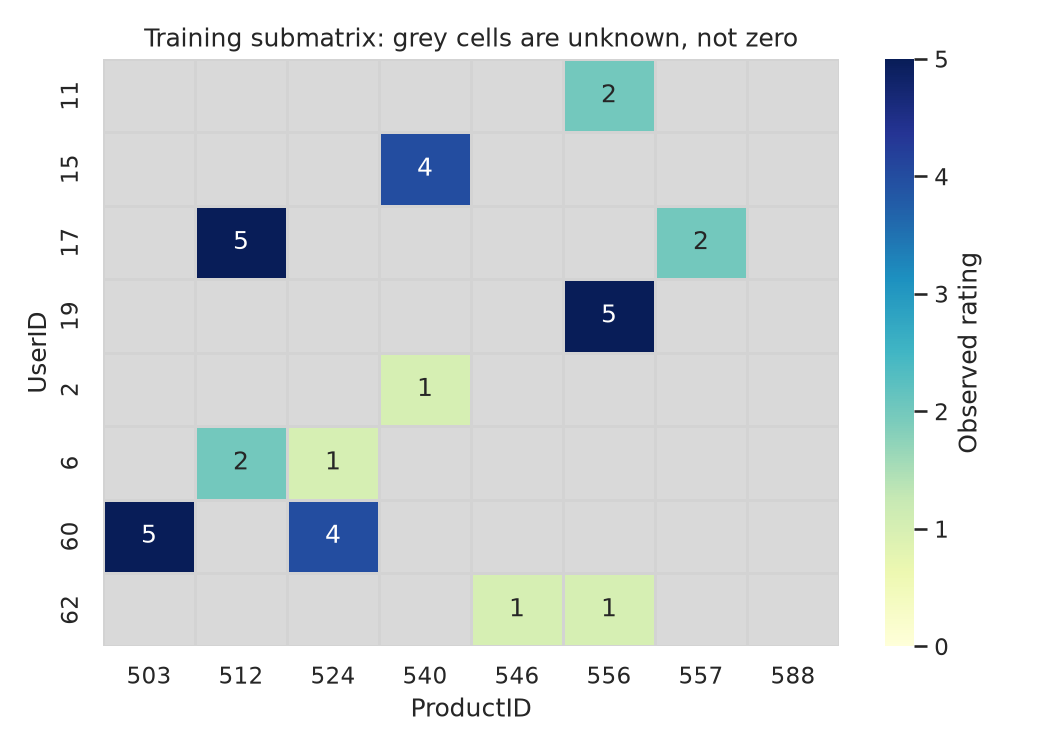

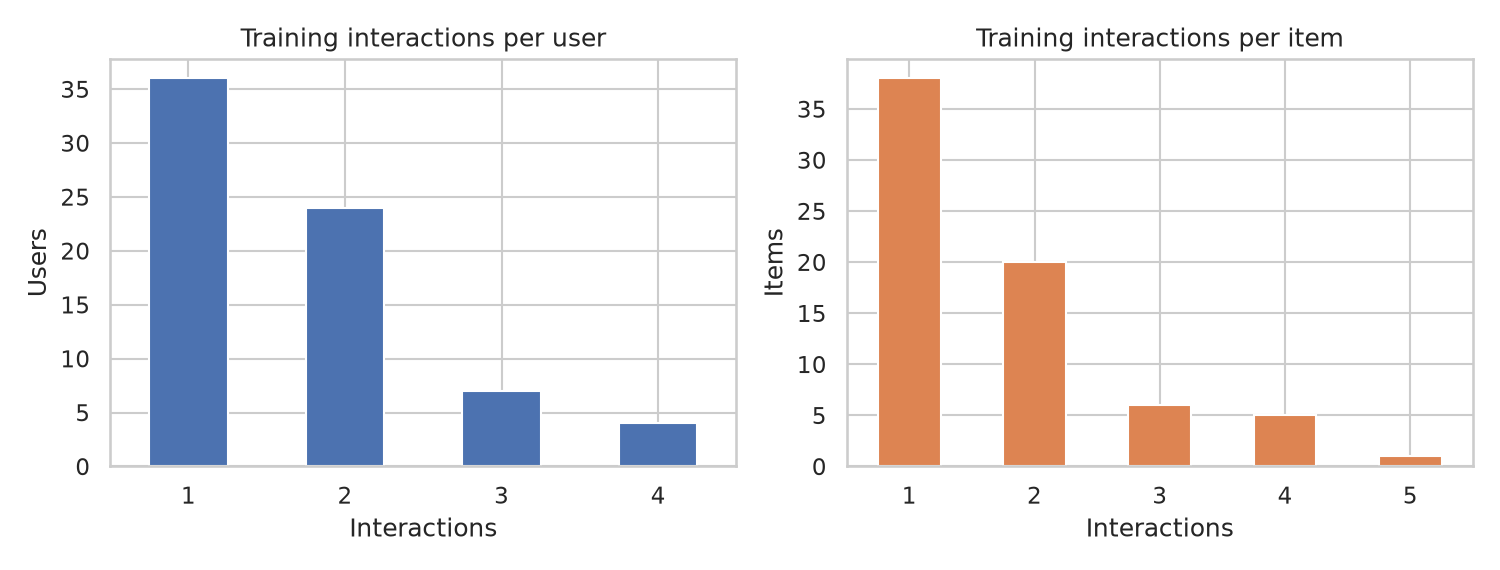

In [3]:
users, items, density, diag = lab.problem2(train, valid, test)
display(Image('figures/masked_submatrix.png'))
display(Image('figures/interaction_counts.png'))

## Problem 3: Popularity Baseline และการวัดผล

**Popularity baseline** = แนะนำสินค้าที่มีคนให้คะแนนบ่อยที่สุดใน training เหมือน "Bestseller list" ทุกคนได้ list เดียวกัน ยกเว้นตัดของที่เคยซื้อไปแล้วออก เสมอกันให้เรียงตาม ProductID

**Metric ที่ใช้ (K = 5)**
- **Precision@5** = จาก 5 อันที่แนะนำ ถูกกี่อัน หารด้วย 5 เสมอ (แม้ list จะสั้นกว่า 5)
- **Recall@5** = จากของที่ลูกค้าชอบจริงทั้งหมด เราเจอกี่อัน
- **NDCG@5** = ให้คะแนนตาม "ลำดับ" ด้วย ถูกที่อันดับ 1 ได้ 1 คะแนน อันดับ 2 ได้ 1/log2(3) = 0.63 ลดหลั่นลงไป แล้วหารด้วยคะแนนสูงสุดที่เป็นไปได้ (IDCG) ให้อยู่ในช่วง 0 ถึง 1

**Relevant item** = Rating >= 4, อยู่ใน catalog 70 ชิ้น, และไม่เคยซื้อใน training วัดผลเฉพาะ user ที่มี relevant item อย่างน้อย 1 ชิ้น และรายงานจำนวน user ที่ถูกตัดออกด้วย

In [4]:
ex, results = lab.problem3(train, valid, test, items, rc.K)


PROBLEM 3.1  POPULARITY BASELINE
Top 10 of the training popularity ranking (count desc, ProductID asc for ties):
ProductID  count
      540      5
      524      4
      546      4
      556      4
      557      4
      588      4
      503      3
      512      3
      533      3
      560      3

Warm user 2: consumed in training ['508', '516', '540', '552'] -> excluded
  Top-5: ['524', '546', '556', '557', '588']
Cold user 3: no training history -> same eligible popularity list
  Top-5: ['540', '524', '546', '556', '557']

PROBLEM 3.2  METRICS: WORKED EXAMPLE AND BASELINE SCORES
Worked example: precision@5 = 0.600000, recall@5 = 0.750000, dcg@5 = 1.930677, ndcg@5 = 0.753698

[valid] users evaluated = 10 (cold 6), holdout users excluded = 20
  Precision@5 = 0.0400 | Recall@5 = 0.2000 | NDCG@5 = 0.0931

[test] users evaluated = 9 (cold 2), holdout users excluded = 23
  Precision@5 = 0.0000 | Recall@5 = 0.0000 | NDCG@5 = 0.0000
UserID  cold_user  n_relevant  hits  precision  recall  

## ผลลัพธ์ที่บันทึก (evidence)
ไฟล์ทั้งหมดอยู่ใน `evidence/` ได้แก่ `results.json`, `split_summary.csv`, `user_mapping.csv`, `item_mapping.csv`, `popularity_ranking.csv`, และ per-user metrics

In [5]:
split.to_csv('evidence/split_summary.csv', index=False)
out = {'source_sha256': rc.sha256_of(rc.EVENTS_CSV), 'split_events': dict(zip(split['partition'], split['events'].astype(int))),
       'train_users': len(users), 'train_items': len(items), 'density': density, 'cold_start': diag,
       'worked_example': ex, 'popularity': results}
print(json.dumps(out, indent=2, default=int))

{
  "source_sha256": "f55471cadb4740a4e15187bea6b8a7b8143f7c9ac3c764269031348fcfbcc079",
  "split_events": {
    "train": 121,
    "valid": 38,
    "test": 41
  },
  "train_users": 71,
  "train_items": 70,
  "density": 0.024346076458752516,
  "cold_start": {
    "valid": {
      "events": 38,
      "events_cold_user": 18,
      "distinct_cold_users": 12,
      "events_unseen_item": 9,
      "distinct_unseen_items": 9
    },
    "test": {
      "events": 41,
      "events_cold_user": 11,
      "distinct_cold_users": 7,
      "events_unseen_item": 17,
      "distinct_unseen_items": 14
    }
  },
  "worked_example": {
    "precision@5": 0.6,
    "recall@5": 0.75,
    "dcg@5": 1.9306765580733931,
    "ndcg@5": 0.75369761125927
  },
  "popularity": {
    "valid": {
      "n_users_evaluated": 10,
      "n_cold_users_evaluated": 6,
      "n_holdout_users_excluded": 20,
      "precision@5": 0.04,
      "recall@5": 0.2,
      "ndcg@5": 0.0930676558073393
    },
    "test": {
      "n_users_eval